# 03 · A lap-time model

Can we predict how fast a clean race lap will be from the tyre, fuel, conditions, traffic and
who is driving?

* **Target:** the lap time relative to that race's median clean lap, in %. This makes Monaco and
  Spa comparable.
* **Validation:** `GroupKFold` with 5 folds grouped by race. Every lap is predicted by a model
  that never saw that race, though it did see the same teams, drivers and circuits elsewhere.
* **Models:**
  * "race median": predict every lap as the race median (the no-skill baseline);
  * a ridge regression with compound, tyre age, fuel, track temperature, car (team × season)
    and driver;
  * LightGBM with every feature, including running position (traffic), weather and circuit.

In [1]:
import matplotlib.pyplot as plt

from f1tyres import plots
from f1tyres.analysis import clean_laps
from f1tyres.config import DATA_PROCESSED
from f1tyres.data import load_tables
from f1tyres.model import cross_validate, cv_metrics, fit_final, importance, prepare, save_model

plots.apply_style()
df = prepare(clean_laps(load_tables()["laps"]))
print(f"{len(df):,} clean laps from {df['RaceId'].nunique()} races")

77,263 clean laps from 89 races


In [2]:
pred = cross_validate(df)
metrics = cv_metrics(pred)
metrics.to_csv(DATA_PROCESSED / "laptime_metrics.csv", index=False)
metrics.round(3)

,model,mae_seconds,median_ae_seconds,mae_pct,r2
0,Race median lap,1.039,0.834,1.174,-0.001
1,Linear (ridge),0.721,0.523,0.816,0.375
2,LightGBM,0.701,0.475,0.792,0.376


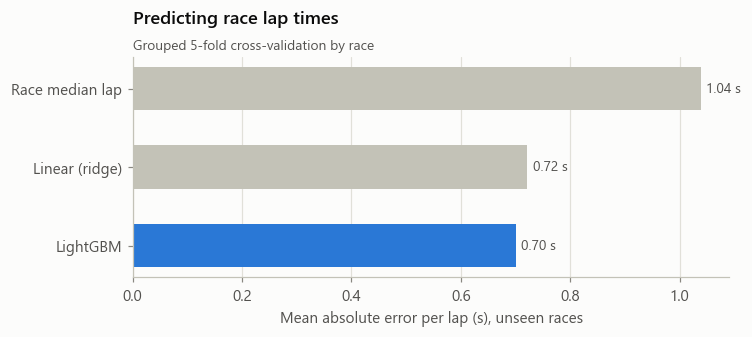

In [3]:
fig = plots.model_comparison(metrics)
plots.save(fig, "laptime_model")
plt.show()

## Errors by compound and tyre age

In [4]:
pred["abs_err_s"] = (pred["pred_lgbm"] - pred["DeltaPct"]).abs() * pred["RaceRef"] / 100
pred.groupby("Compound", observed=True)["abs_err_s"].agg(["mean", "median", "size"]).round(3)

,mean,median,size
Compound,,,
HARD,0.622,0.443,37654
MEDIUM,0.785,0.504,30554
SOFT,0.746,0.522,9055


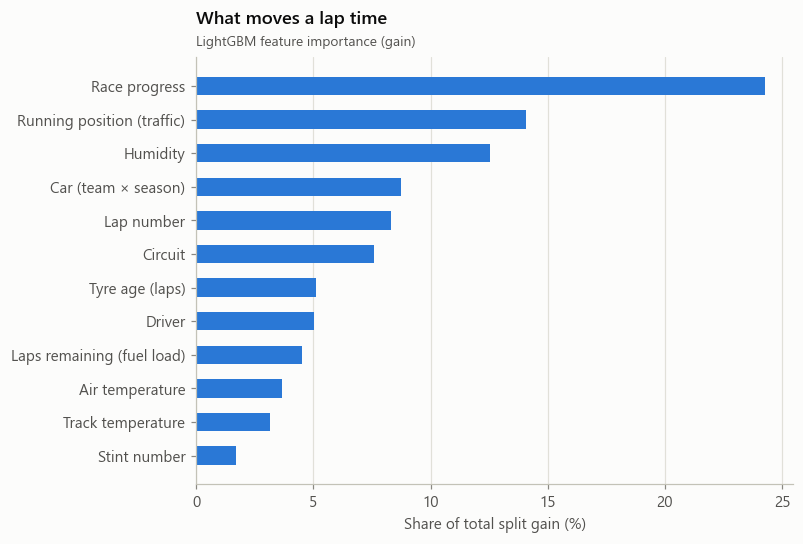

WindowsPath('D:/motorsport projects/f1-tyre-strategy-analysis/models/laptime_model.joblib')

In [5]:
model = fit_final(df)
imp = importance(model)
imp.to_csv(DATA_PROCESSED / "laptime_importance.csv", index=False)
fig = plots.importance(imp)
plots.save(fig, "laptime_importance")
plt.show()
save_model(model)  # LightGBM: the most accurate model on unseen races

**Reading it.**

* **Both models cut the error by about a third compared with the race median.** LightGBM edges
  the ridge regression, mostly through smaller *typical* errors (median error 0.48 s vs 0.52 s).
  R² is the same, so it doesn't fix the large misses either.
* **The ridge model is a strong baseline.** Once fuel, tyre age and the car (team × season) are
  accounted for, most effects simply add up. On an early subset of the data the ridge model
  was actually ahead, and LightGBM only pulled in front with all four seasons.
* Even the best model is off by about 0.7 s per lap on average. Lap times also depend on things
  we don't observe: tyre management, the strategy instructions of the moment, and dirty air from
  the car in front.